# Modelling Notebook: Which stores earn more, and how would a new store perform?
**ANCP M4 Modelling and the store simulation | Group G | 7-Eleven India dataset (synthetic)**

Team: Aarshi Singh, AswinPrabhu D, Devadath Varma

### The whole notebook in plain words
We answer two questions with the simplest models that work:

| Question | Model | Why this model |
|---|---|---|
| 1. Is a store-month **profitable**? (yes or no) | Logistic regression (random forest as a comparison) | Easy to explain, and it can be compared fairly against simple baselines |
| 2. How much **revenue** would a new site make? | Ridge regression on log revenue | Only 60 stores, so a simple, stable model is safer than a complex one |
| 3. What could happen **over 3 years**, with uncertainty? | Monte Carlo simulation on top of model 2 | Turns one number into a range, and adds costs, growth and ramp-up |

**Read first:** the data is **synthetic** (no real 7-Eleven stores, customers or transactions). Scores show that the method works on this workbook, not on real stores. Set-up costs, transport costs, growth and ramp-up are **assumptions**, not data.

## Step 0. Load the data

In [1]:
import os, re, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, LeaveOneOut, cross_val_predict
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, mean_absolute_error, r2_score)
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', None)

DATA = 'CP_Dataset.xlsx' if os.path.exists('CP_Dataset.xlsx') else '/mnt/user-data/uploads/CP_Dataset.xlsx'
sheets = pd.read_excel(DATA, sheet_name=None)
for name in sheets:     # tidy the column names (the workbook has stray spaces)
    sheets[name].columns = sheets[name].columns.str.strip().str.replace(r'\s+', '_', regex=True)

monthly = sheets['Store_Monthly_Performance']   # 720 rows: 60 stores x 12 months
stores  = sheets['Store_Master']                # 60 stores
locs    = sheets['Location_Features']           # 300 candidate locations
print('Store-months:', len(monthly), '| stores:', monthly.store_id.nunique(), '| locations:', len(locs))

Store-months: 720 | stores: 60 | locations: 300


### Data-compliance checks (these must pass before any modelling)
The workbook's own rules (from the D2 audit): operating profit must equal revenue minus the five cost lines, and the profitable flag must match the sign of profit.

In [2]:
identity = (monthly.monthly_revenue_inr - monthly.monthly_rent_inr - monthly.monthly_labor_cost_inr
            - monthly.monthly_utilities_inr - monthly.shrinkage_cost_inr - monthly.estimated_cogs_inr)
print('Profit = revenue - rent - labour - utilities - shrinkage - COGS ?  max difference:', round((identity - monthly.estimated_operating_profit_inr).abs().max(), 4))
print('Profitable flag matches sign of profit for', round(float(((monthly.estimated_operating_profit_inr > 0).astype(int) == monthly.profitable_flag).mean()), 3), 'of rows')
print('All store_ids in Store_Master:', monthly.store_id.isin(stores.store_id).all(), '| all location_ids in Location_Features:', monthly.location_id.isin(locs.location_id).all())
assert (identity - monthly.estimated_operating_profit_inr).abs().max() < 1
assert monthly.store_id.isin(stores.store_id).all() and monthly.location_id.isin(locs.location_id).all()

Profit = revenue - rent - labour - utilities - shrinkage - COGS ?  max difference: 0.0
Profitable flag matches sign of profit for 1.0 of rows
All store_ids in Store_Master: True | all location_ids in Location_Features: True


## Step 1. Build the modelling tables
- **Store-month table (720 rows):** used for the yes/no profit model and the baseline comparison.
- **Store table (60 rows):** used for the revenue model that the simulator needs. One row per store, with its average monthly revenue and its location features.

**What we leave out on purpose (leakage):** rent share and operating profit. They are built from the same numbers as the target, so using them would make the model look better than it is.

In [3]:
FEATURES = ['daily_footfall_estimate', 'transit_nodes_within_500m', 'synthetic_demand_index',
            'convenience_competitors_within_1km', 'avg_monthly_income_inr', 'store_size_sqft']

# Store-month table
sm = monthly[['store_id','location_id','month','monthly_revenue_inr','profitable_flag']].merge(
        stores[['store_id','store_format','store_size_sqft']], on='store_id').merge(
        locs[['location_id'] + [f for f in FEATURES if f != 'store_size_sqft'] + ['monthly_rent_estimate_inr']], on='location_id')
sm = pd.get_dummies(sm, columns=['store_format'], dtype=int)
CLASS_FEATURES = ['daily_footfall_estimate','transit_nodes_within_500m','synthetic_demand_index',
                  'monthly_rent_estimate_inr','store_size_sqft'] + [c for c in sm.columns if c.startswith('store_format_')]

# Store table (60 rows)
store = monthly.groupby('store_id').agg(revenue=('monthly_revenue_inr','mean'), location_id=('location_id','first'),
                                        city=('city','first')).reset_index()
store = store.merge(stores[['store_id','store_size_sqft']], on='store_id').merge(locs.drop(columns=['city']), on='location_id')
print('Share of store-months that are profitable:', round(float(sm.profitable_flag.mean()), 3))
print('Store table:', store.shape)

Share of store-months that are profitable: 0.585
Store table: (60, 25)


## Step 2. The validation rule: split by store
Each store appears in 12 rows. If one store's rows were in both the training and test data, the model would just recognise the store and the scores would be too good. So the test data always contains **stores the model has never seen** (5 folds, `GroupKFold`).

In [4]:
folds = list(GroupKFold(n_splits=5).split(sm, groups=sm['store_id']))
for i, (tr, te) in enumerate(folds, 1):
    shared = set(sm.iloc[tr].store_id) & set(sm.iloc[te].store_id)
    print(f'Fold {i}: train stores {sm.iloc[tr].store_id.nunique()}, test stores {sm.iloc[te].store_id.nunique()}, stores in both: {len(shared)}')
    assert len(shared) == 0

Fold 1: train stores 48, test stores 12, stores in both: 0
Fold 2: train stores 48, test stores 12, stores in both: 0
Fold 3: train stores 48, test stores 12, stores in both: 0
Fold 4: train stores 48, test stores 12, stores in both: 0
Fold 5: train stores 48, test stores 12, stores in both: 0


## Step 3. Model 1: is a store-month profitable? (baselines first)
We always start with simple rules, so we can tell whether a model adds anything.
1. **Baseline A:** guess the overall profit rate for everyone.
2. **Baseline B:** use the profit rate of the store's format (e.g. high street vs transit-adjacent).
3. **Logistic regression:** weighs footfall, transit, demand, rent and size together.
4. **Random forest (depth 4):** a tree-based comparison.

,model,precision,recall,f1,roc_auc,pr_auc
0,Baseline A: overall rate,0.585,1.000,0.738,0.469,0.564
1,Baseline B: rate by store format,0.643,0.789,0.709,0.597,0.623
2,Logistic regression,0.863,0.886,0.875,0.931,0.945
3,Random forest (depth 4),0.844,0.914,0.878,0.923,0.933


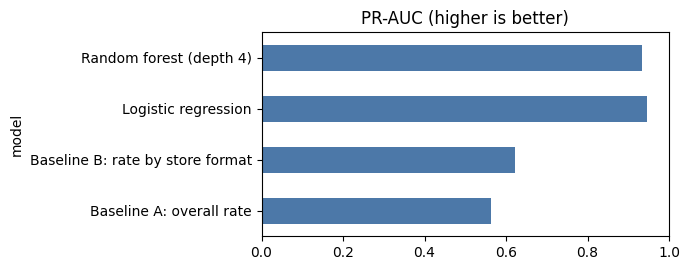

In [5]:
y = sm['profitable_flag']
results = []

def evaluate(name, predict):
    prob = pd.Series(0.0, index=sm.index)
    for tr, te in folds:
        prob.iloc[te] = predict(sm.iloc[tr], sm.iloc[te])
    pred = (prob >= 0.5).astype(int)
    results.append({'model': name, 'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred),
                    'f1': f1_score(y, pred), 'roc_auc': roc_auc_score(y, prob), 'pr_auc': average_precision_score(y, prob)})

evaluate('Baseline A: overall rate', lambda tr, te: tr.profitable_flag.mean())

fmt_cols = [c for c in CLASS_FEATURES if c.startswith('store_format_')]
def by_format(tr, te):
    rate = {c: tr.loc[tr[c] == 1, 'profitable_flag'].mean() for c in fmt_cols}
    return te[fmt_cols].apply(lambda r: rate[[c for c in fmt_cols if r[c] == 1][0]], axis=1)
evaluate('Baseline B: rate by store format', by_format)

def logistic(tr, te):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    return m.fit(tr[CLASS_FEATURES], tr.profitable_flag).predict_proba(te[CLASS_FEATURES])[:, 1]
evaluate('Logistic regression', logistic)

def forest(tr, te):
    m = RandomForestClassifier(n_estimators=200, max_depth=4, random_state=42)
    return m.fit(tr[CLASS_FEATURES], tr.profitable_flag).predict_proba(te[CLASS_FEATURES])[:, 1]
evaluate('Random forest (depth 4)', forest)

class_table = pd.DataFrame(results).round(3); display(class_table)
ax = class_table.set_index('model')['pr_auc'].plot.barh(color='#4C78A8', figsize=(7, 2.8), title='PR-AUC (higher is better)')
ax.set_xlim(0, 1); plt.tight_layout(); plt.savefig('fig_model_comparison.png', dpi=150); plt.show()

**How to read this**
- **Precision:** of the store-months we call profitable, how many really are.
- **Recall:** of the truly profitable store-months, how many we catch.
- **PR-AUC / ROC-AUC:** how well the model ranks profitable above unprofitable (1.0 is perfect).
- The models clearly beat both baselines, and logistic regression is as good as the random forest. We therefore choose the **simpler** one, because it is easier to explain.
- **Caution:** the scores are strong partly because the synthetic data were built from these same factors. They do not prove real-world accuracy.

## Step 4. Model 2: how much revenue would a new site make? (the model the simulator uses)
**Ridge regression** is ordinary linear regression with a small penalty that keeps the coefficients from swinging wildly. That matters with only 60 stores.

**Why log revenue?** It keeps predicted revenue above zero, and it treats a 10% error the same for small and large stores.

**Validation:** leave-one-store-out. Remove one store, fit on the other 59, predict the removed store, and repeat 60 times.

Cross-validated R2 (log revenue): 0.94
Typical error on the log scale (loo_sd): 0.120  (about 13% either way)


,standardised coefficient
daily_footfall_estimate,0.287
synthetic_demand_index,0.146
transit_nodes_within_500m,0.093
store_size_sqft,0.010
avg_monthly_income_inr,0.003
convenience_competitors_within_1km,-0.061


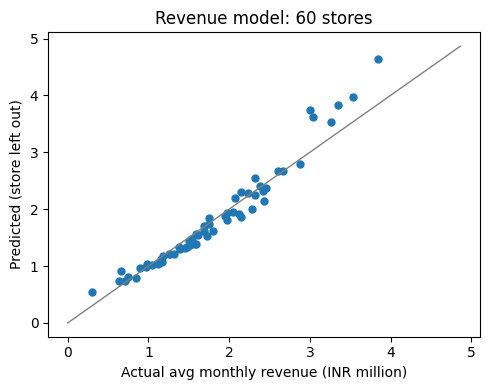

In [6]:
X, ylog = store[FEATURES], np.log(store['revenue'])
rev_model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
loo_pred = cross_val_predict(rev_model, X, ylog, cv=LeaveOneOut())
cv_r2 = 1 - ((ylog - loo_pred) ** 2).sum() / ((ylog - ylog.mean()) ** 2).sum()
loo_sd = float(np.std(ylog - loo_pred))
rev_model.fit(X, ylog)
store['loo_revenue'] = np.exp(loo_pred)
print(f'Cross-validated R2 (log revenue): {cv_r2:.2f}')
print(f'Typical error on the log scale (loo_sd): {loo_sd:.3f}  (about {100*(np.exp(loo_sd)-1):.0f}% either way)')

coef = pd.Series(rev_model.named_steps['ridge'].coef_, index=FEATURES).round(3).sort_values(ascending=False)
display(coef.rename('standardised coefficient').to_frame())

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(store['revenue']/1e6, store['loo_revenue']/1e6, s=25)
lim = [0, max(store['revenue'].max(), store['loo_revenue'].max())/1e6 * 1.05]
ax.plot(lim, lim, color='grey', lw=1); ax.set_xlabel('Actual avg monthly revenue (INR million)'); ax.set_ylabel('Predicted (store left out)')
ax.set_title('Revenue model: 60 stores'); plt.tight_layout(); plt.savefig('fig_revenue_model.png', dpi=150); plt.show()

**How to read the coefficients:** all features are put on the same scale first, so the sign shows direction and the size shows relative strength. Footfall carries the most weight, in line with the EDA (Spearman 0.93 with revenue). Features that move together (footfall, transit, demand) share credit, which is why a few coefficients look small or even negative. Do not read single coefficients as causes.

**Why we did not use rent here:** rent mainly affects *cost*, not revenue (EDA: Spearman 0.02 with revenue). In the simulation, rent is used on the cost side.

For comparison, the D4 revenue models on store-month rows (raw revenue, grouped by store) score lower, as shown below. The two are not directly comparable: different target (log vs raw) and different rows (60 stores vs 720 store-months).

In [7]:
yrev = sm['monthly_revenue_inr']; rows = []
def eval_rev(name, predict):
    pred = pd.Series(0.0, index=sm.index)
    for tr, te in folds: pred.iloc[te] = predict(sm.iloc[tr], sm.iloc[te])
    rows.append({'model': name, 'MAE_inr': mean_absolute_error(yrev, pred), 'R2': r2_score(yrev, pred)})
eval_rev('Baseline: mean revenue', lambda tr, te: tr.monthly_revenue_inr.mean())
eval_rev('Linear: footfall only', lambda tr, te: LinearRegression().fit(tr[['daily_footfall_estimate']], tr.monthly_revenue_inr).predict(te[['daily_footfall_estimate']]))
eval_rev('Linear: all features', lambda tr, te: LinearRegression().fit(tr[CLASS_FEATURES], tr.monthly_revenue_inr).predict(te[CLASS_FEATURES]))
display(pd.DataFrame(rows).round(2))

,model,MAE_inr,R2
0,Baseline: mean revenue,669459.91,-0.02
1,Linear: footfall only,376295.50,0.66
2,Linear: all features,330411.41,0.74


## Step 5. What the data tells us about costs and timing
The simulator takes these straight from the workbook (so it complies with the dataset):
- **COGS and shrinkage** as a share of revenue.
- **Labour and utilities** as the median monthly cost.
- **Seasonality:** the average revenue in each calendar month relative to the yearly average (one year of data only).
- **Month-to-month noise:** how much a store's monthly revenue varies after removing seasonality.
- **Peer benchmark:** the median revenue of existing stores in each city.

In [8]:
costs = {'cogs_share': float((monthly.estimated_cogs_inr / monthly.monthly_revenue_inr).mean()),
         'shrink_share': float((monthly.shrinkage_cost_inr / monthly.monthly_revenue_inr).mean()),
         'labour': float(monthly.monthly_labor_cost_inr.median()),
         'utilities': float(monthly.monthly_utilities_inr.median())}
m2 = monthly.copy()
m2['ratio'] = m2.monthly_revenue_inr / m2.groupby('store_id').monthly_revenue_inr.transform('mean')
season = m2.groupby('month')['ratio'].mean(); season = (season / season.mean()).reindex(range(1, 13)).values
noise_sd = float(np.log(m2['ratio'] / season[m2['month'].values - 1]).std())
peer_by_city = store.groupby('city')['revenue'].median().to_dict()
median_size = float(store.store_size_sqft.median())

print({k: round(v, 4) for k, v in costs.items()})
print('Seasonality index Jan..Dec:', np.round(season, 3))
print('Month-to-month noise (log sd):', round(noise_sd, 3))
print('Median store revenue by city (INR):', {k: round(v) for k, v in peer_by_city.items()})

{'cogs_share': 0.7189, 'shrink_share': 0.0212, 'labour': 143685.5, 'utilities': 33350.5}
Seasonality index Jan..Dec: [0.989 1.068 1.059 1.092 1.096 1.01  0.984 0.909 0.851 0.976 0.953 1.013]
Month-to-month noise (log sd): 0.192
Median store revenue by city (INR): {'Bengaluru': 1584012, 'Chennai': 1187484, 'Delhi': 2075577, 'Hyderabad': 1449806, 'Mumbai': 1828223, 'Pune': 1747515}


## Step 6. The simulation: from one number to a 3-year range
For one candidate site, each of the 5,000 simulated futures does the following:
1. **Starting revenue:** 75% from the ridge model plus 25% from the median store in the same city.
2. **Location uncertainty:** multiply by a random factor sized from the model's leave-one-out error.
3. **Growth:** draw a yearly growth rate (assumption: 4% on average, 3% spread). The data covers 2024 only, so growth cannot be estimated from it.
4. **Ramp-up:** a new store starts at 60% of mature revenue and reaches 100% after 6 months (assumption).
5. **Seasonality and noise:** from the data (Step 5).
6. **Costs:** COGS and shrinkage (from data) and marketing and payment fees (assumption) scale with revenue. Rent, labour, utilities, **transport**, maintenance, insurance and POS fees are fixed monthly costs that rise 5% a year (assumption). Set-up cost, contingency and a security deposit are paid at the start.
7. **Outputs:** profit each month, cumulative profit after upfront costs, and the month the store pays back its upfront cost.

The percentile range **P10 to P90** is the middle 80% of the 5,000 futures.

In [9]:
ASSUMPTIONS = {   # ASSUMPTIONS: none of these are in the dataset. Replace with real quotes.
    'capex_items_inr': {'fit_out_and_interiors': 800_000, 'refrigeration_and_equipment': 600_000, 'signage_and_branding': 120_000,
                        'pos_and_it_setup': 100_000, 'licences_and_permits': 80_000, 'initial_inventory': 300_000,
                        'pre_opening_marketing_and_training': 100_000},
    'contingency_pct': 0.10, 'deposit_months_of_rent': 3, 'deposit_refundable': True,
    'distance_to_dc_km': 25, 'deliveries_per_week': 10, 'transport_cost_per_km_inr': 18,
    'marketing_pct_revenue': 0.01, 'payment_fee_pct_revenue': 0.004,
    'maintenance_inr': 15_000, 'insurance_licences_inr': 12_000, 'tech_pos_inr': 10_000,
    'annual_growth_mean': 0.04, 'annual_growth_sd': 0.03, 'ramp_start': 0.60, 'ramp_months': 6,
    'cost_inflation': 0.05, 'peer_weight': 0.25, 'opening_month': 1, 'horizon_months': 36, 'n_sims': 5000}

def simulate_site(site, **override):
    a = {**ASSUMPTIONS, **override}
    rng = np.random.default_rng(42)
    n, H = a['n_sims'], a['horizon_months']
    model_rev = float(np.exp(rev_model.predict(pd.DataFrame([site])[FEATURES])[0]))
    peer_rev = peer_by_city.get(site['city'], np.median(list(peer_by_city.values())))
    base = (1 - a['peer_weight']) * model_rev + a['peer_weight'] * peer_rev

    t = np.arange(H)
    site_effect = np.exp(rng.normal(0, loo_sd, (n, 1)))
    growth = rng.normal(a['annual_growth_mean'], a['annual_growth_sd'], (n, 1))
    growth_path = (1 + growth) ** (t / 12)
    ramp = np.minimum(1.0, a['ramp_start'] + (1 - a['ramp_start']) * t / max(a['ramp_months'], 1))
    seasonal = season[(a['opening_month'] - 1 + t) % 12]
    noise = np.exp(rng.normal(0, noise_sd, (n, H)) - noise_sd ** 2 / 2)
    revenue = base * site_effect * growth_path * ramp * seasonal * noise

    setup = sum(a['capex_items_inr'].values()); contingency = setup * a['contingency_pct']
    deposit = site['monthly_rent_inr'] * a['deposit_months_of_rent']; capex = setup + contingency + deposit
    transport = a['distance_to_dc_km'] * 2 * a['deliveries_per_week'] * 52 / 12 * a['transport_cost_per_km_inr']
    other_fixed = a['maintenance_inr'] + a['insurance_licences_inr'] + a['tech_pos_inr']
    inflation = (1 + a['cost_inflation']) ** (t // 12)
    fixed = (site['monthly_rent_inr'] + costs['labour'] + costs['utilities'] + transport + other_fixed) * inflation
    var_share = costs['cogs_share'] + costs['shrink_share'] + a['marketing_pct_revenue'] + a['payment_fee_pct_revenue']
    profit = revenue - fixed - revenue * var_share
    cumulative = np.cumsum(profit, axis=1) - capex
    paid = cumulative >= 0
    payback = np.where(paid.any(axis=1), paid.argmax(axis=1) + 1, np.nan)
    end_cum = cumulative[:, -1] + (deposit if a['deposit_refundable'] else 0)
    pct = lambda arr, q: np.percentile(arr, q, axis=0)
    return {'model_rev': model_rev, 'peer_rev': peer_rev, 'base': base, 'capex': capex, 'setup': setup, 'contingency': contingency,
            'deposit': deposit, 'transport': transport,
            'p_profit_m12': float((profit[:, min(12, H) - 1] > 0).mean()), 'p_payback': float(paid.any(axis=1).mean()),
            'median_payback': float(np.nanmedian(payback)) if paid.any() else None,
            'growth_pct': {q: float(np.percentile(revenue[:, -12:].mean(1) / revenue[:, :12].mean(1) - 1, q) * 100) for q in (10, 50, 90)},
            'end_cum': {q: float(np.percentile(end_cum, q)) for q in (10, 50, 90)},
            'series': {'revenue': [pct(revenue, q) for q in (10, 50, 90)], 'profit': [pct(profit, q) for q in (10, 50, 90)],
                       'cumulative': [pct(cumulative, q) for q in (10, 50, 90)]}}
print('Simulation function ready.')

Simulation function ready.


### Run it for an example site
Change the numbers to try another site. The site is made up (not a location from the workbook).

Mature monthly revenue  : model INR 1,351,042 | same-city peers INR 1,584,012 | used INR 1,409,285
Upfront cost            : INR 3,360,000 (set-up 2,100,000 + contingency 210,000 + deposit 1,050,000)
Transport per month     : INR 39,000
Chance of a monthly profit in month 12 : 1%
Chance of paying back upfront cost     : 0% (median payback month: None)
Revenue growth, last 12 vs first 12 months (includes ramp-up): P10 9% | median 23% | P90 39%
Cumulative profit after upfront costs (deposit returned): P10 INR -14,416,689 | median INR -12,429,207 | P90 INR -10,195,404


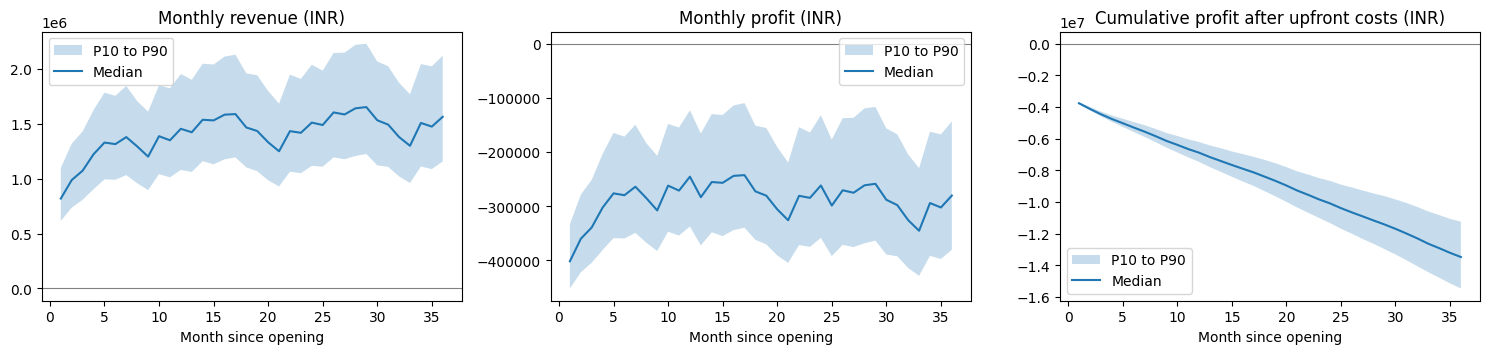

In [10]:
my_site = {'daily_footfall_estimate': 7000, 'transit_nodes_within_500m': 2, 'synthetic_demand_index': 5.0,
           'convenience_competitors_within_1km': 8, 'avg_monthly_income_inr': 30000, 'store_size_sqft': 850,
           'city': 'Bengaluru', 'monthly_rent_inr': 350_000}
res = simulate_site(my_site)
print(f"Mature monthly revenue  : model INR {res['model_rev']:,.0f} | same-city peers INR {res['peer_rev']:,.0f} | used INR {res['base']:,.0f}")
print(f"Upfront cost            : INR {res['capex']:,.0f} (set-up {res['setup']:,.0f} + contingency {res['contingency']:,.0f} + deposit {res['deposit']:,.0f})")
print(f"Transport per month     : INR {res['transport']:,.0f}")
print(f"Chance of a monthly profit in month 12 : {res['p_profit_m12']:.0%}")
print(f"Chance of paying back upfront cost     : {res['p_payback']:.0%} (median payback month: {res['median_payback']})")
g = res['growth_pct']; print(f"Revenue growth, last 12 vs first 12 months (includes ramp-up): P10 {g[10]:.0f}% | median {g[50]:.0f}% | P90 {g[90]:.0f}%")
c = res['end_cum']; print(f"Cumulative profit after upfront costs (deposit returned): P10 INR {c[10]:,.0f} | median INR {c[50]:,.0f} | P90 INR {c[90]:,.0f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a_, key, title in zip(ax, ['revenue', 'profit', 'cumulative'], ['Monthly revenue (INR)', 'Monthly profit (INR)', 'Cumulative profit after upfront costs (INR)']):
    lo, mid, hi = res['series'][key]; x = np.arange(1, len(mid) + 1)
    a_.fill_between(x, lo, hi, alpha=0.25, label='P10 to P90'); a_.plot(x, mid, label='Median'); a_.axhline(0, color='grey', lw=0.8)
    a_.set_title(title); a_.set_xlabel('Month since opening'); a_.legend()
plt.tight_layout(); plt.savefig('fig_simulation.png', dpi=150); plt.show()

**How to read the example:** this made-up site has high rent for its footfall, so it loses money in most simulated futures. That is not an error: it shows the simulator separating good sites from poor ones. The wide band is the uncertainty, and the growth figure is mostly the new-store ramp-up plus the 4% growth assumption.

## Step 7. Backtest on the 60 existing stores
For each existing store: predict its average monthly profit using the revenue model (with that store left out) and **only the costs that exist in the dataset** (COGS, shrinkage, rent, labour, utilities), then compare with the dataset's actual profit. Transport, set-up and the other assumed costs are not part of this test.

In [11]:
act = monthly.groupby('store_id').agg(actual=('estimated_operating_profit_inr', 'mean'), rent=('monthly_rent_inr', 'mean')).reset_index()
bt = store.merge(act, on='store_id')
bt['predicted'] = bt.loo_revenue * (1 - costs['cogs_share'] - costs['shrink_share']) - bt.rent - costs['labour'] - costs['utilities']
spearman = bt[['predicted', 'actual']].corr(method='spearman').iloc[0, 1]
sign_ok = float(((bt.predicted > 0) == (bt.actual > 0)).mean()); mae = float((bt.predicted - bt.actual).abs().mean())
print(f'Spearman rank agreement: {spearman:.2f} | profit-or-loss called correctly for {sign_ok:.0%} of stores | average error INR {mae:,.0f} per month')

Spearman rank agreement: 0.98 | profit-or-loss called correctly for 95% of stores | average error INR 42,440 per month


A high score here is partly because the synthetic profits are built from the same factors. On real data, expect this to be lower.

## Step 8. Consistency checks (notebook = dataset = simulator)
These checks confirm the notebook matches the saved simulator (`store_simulation.py` and `lovable_calibration.json`) and the workbook, so the three never disagree.

In [12]:
checks = []
def check(name, ok): checks.append((name, bool(ok))); print(('PASS  ' if ok else 'FAIL  ') + name)

check('Upfront cost for the example site = INR 3,360,000', abs(res['capex'] - 3_360_000) < 1)
check('Transport per month = INR 39,000', abs(res['transport'] - 39_000) < 1)
check('Model revenue for the example site is about INR 1,351,042', abs(res['model_rev'] - 1_351_042) / 1_351_042 < 0.005)
check('Same-city peer revenue (Bengaluru) is about INR 1,584,012', abs(res['peer_rev'] - 1_584_012) / 1_584_012 < 0.005)
check('Leave-one-store-out R2 is about 0.94', abs(cv_r2 - 0.94) < 0.01)
check('Median cumulative profit about INR -12.4 million (same as store_simulation.py)', abs(res['end_cum'][50] + 12_429_207) / 12_429_207 < 0.02)

cal_path = 'lovable_calibration.json' if os.path.exists('lovable_calibration.json') else '/mnt/user-data/outputs/lovable_calibration.json'
if os.path.exists(cal_path):
    cal = json.load(open(cal_path)); me = rev_model.named_steps
    check('Ridge coefficients equal lovable_calibration.json', np.allclose(me['ridge'].coef_, cal['ridge_coef'], atol=1e-6))
    check('Scaler means equal lovable_calibration.json', np.allclose(me['standardscaler'].mean_, cal['scaler_mean'], rtol=1e-6))
    check('Seasonality equals lovable_calibration.json', np.allclose(season, cal['season_index_jan_to_dec'], atol=1e-6))
    check('COGS and shrinkage shares equal lovable_calibration.json', np.isclose(costs['cogs_share'], cal['cogs_share']) and np.isclose(costs['shrink_share'], cal['shrink_share']))
    check('Peer medians equal lovable_calibration.json', all(np.isclose(peer_by_city[k], v) for k, v in cal['peer_median_revenue_by_city'].items()))
else:
    print('lovable_calibration.json not found: skipped comparison with the saved calibration')
print(); print('All checks passed' if all(ok for _, ok in checks) else 'Some checks FAILED: review before using')

PASS  Upfront cost for the example site = INR 3,360,000
PASS  Transport per month = INR 39,000
PASS  Model revenue for the example site is about INR 1,351,042
PASS  Same-city peer revenue (Bengaluru) is about INR 1,584,012
PASS  Leave-one-store-out R2 is about 0.94
PASS  Median cumulative profit about INR -12.4 million (same as store_simulation.py)
PASS  Ridge coefficients equal lovable_calibration.json
PASS  Scaler means equal lovable_calibration.json
PASS  Seasonality equals lovable_calibration.json
PASS  COGS and shrinkage shares equal lovable_calibration.json
PASS  Peer medians equal lovable_calibration.json

All checks passed


## Summary
| Item | Choice | Evidence in this notebook |
|---|---|---|
| Profitable or not | Logistic regression | Beats both baselines; as good as a random forest, and easier to explain |
| Revenue for a new site | Ridge regression on log revenue | Leave-one-store-out R2 about 0.94 on 60 stores |
| Future range | Monte Carlo simulation (5,000 paths, 36 months) | Uses costs, seasonality and noise from the data |
| Validation | Split by store; leave-one-store-out | No store is in both training and test data |
| Left out on purpose | Rent share, operating profit | They are built from the target (leakage) |

**Limits (for the report):** the data is synthetic, so scores do not prove real-world accuracy. Only 60 stores are labelled, so estimates are uncertain. Growth, ramp-up, set-up cost, transport and other extra costs are assumptions. Location variables are placeholders until replaced with verified public or internal data. The simulator is decision support, not a forecast.